In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

In [2]:
# Step 1: Extended dataset
data = {
    'Experience': list(range(1, 21)),
    'Salary': [
        50000, 55000, 62000, 70000, 85000,
        100000, 120000, 140000, 160000, 180000,
        200000, 220000, 240000, 260000, 280000,
        300000, 320000, 340000, 360000, 400000
    ]
}

# Step 2: Load into DataFrame
df = pd.DataFrame(data)
df

,Experience,Salary
0,1,50000
1,2,55000
2,3,62000
3,4,70000
4,5,85000
5,6,100000
6,7,120000
7,8,140000
8,9,160000
9,10,180000


In [3]:
# Step 3: Split into X and y
X = df[['Experience']].values
y = df['Salary'].values

# Step 4: Fit Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X, y)

# Step 5: Fit Polynomial Regression (you can try degree=3 or 4 too)
poly_feat3 = PolynomialFeatures(degree=3) # X^3
X_poly3 = poly_feat3.fit_transform(X)
lin_reg_poly3 = LinearRegression()
lin_reg_poly3.fit(X_poly3, y)

# Step 6: Fit Polynomial Regression degree=4
poly_feat4 = PolynomialFeatures(degree=4) #X^4
X_poly4 = poly_feat4.fit_transform(X)
lin_reg_poly4 = LinearRegression()
lin_reg_poly4.fit(X_poly4, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


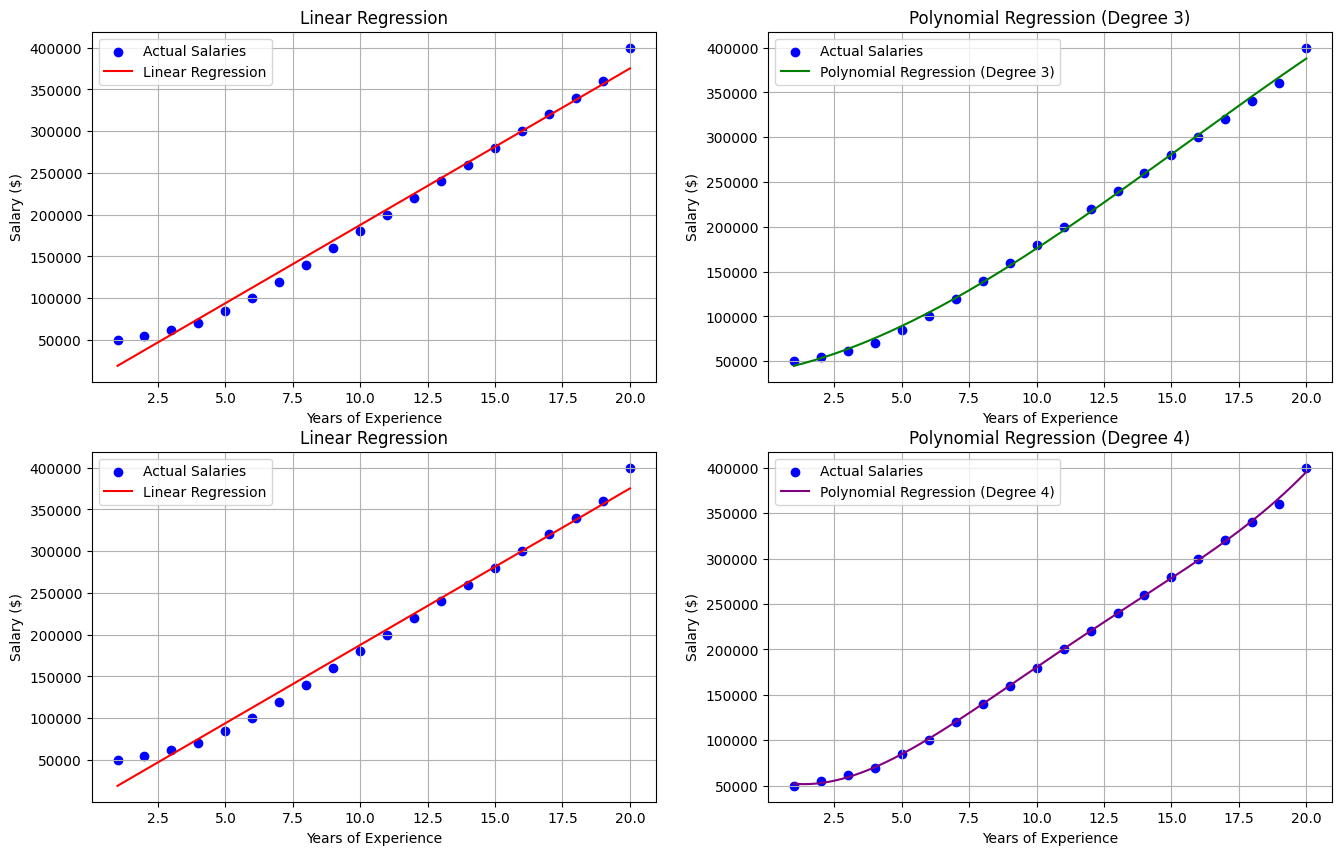

In [4]:
# Step 6: Prepare X_grid for smoother curves
X_grid = np.arange(X.min(), X.max() + 0.1, 0.1).reshape(-1, 1)

# Step 7: Create 4 Subplots
plt.figure(figsize=(16, 10))

# Subplot 1: Linear Regression
plt.subplot(2, 2, 1)
plt.scatter(X, y, color='blue', label='Actual Salaries')
plt.plot(X, lin_reg.predict(X), color='red', label='Linear Regression')
plt.title('Linear Regression')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.grid(True)
plt.legend()

# Subplot 2: Polynomial Regression Degree 3
plt.subplot(2, 2, 2)
plt.scatter(X, y, color='blue', label='Actual Salaries')
plt.plot(X_grid, lin_reg_poly3.predict(poly_feat3.transform(X_grid)), 
         color='green', label='Polynomial Regression (Degree 3)')
plt.title('Polynomial Regression (Degree 3)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.grid(True)
plt.legend()

# Subplot 3: Linear Regression
plt.subplot(2, 2, 3)
plt.scatter(X, y, color='blue', label='Actual Salaries')
plt.plot(X, lin_reg.predict(X), color='red', label='Linear Regression')
plt.title('Linear Regression')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.grid(True)
plt.legend()

# Subplot 4: Polynomial Regression Degree 4
plt.subplot(2, 2, 4)
plt.scatter(X, y, color='blue', label='Actual Salaries')
plt.plot(X_grid, lin_reg_poly4.predict(poly_feat4.transform(X_grid)), 
         color='purple', label='Polynomial Regression (Degree 4)')
plt.title('Polynomial Regression (Degree 4)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.grid(True)
plt.legend()

plt.show()


In [6]:
# Step 8: Prediction
experience_value = float(input("Enter years of experience: "))

linear_pred = lin_reg.predict([[experience_value]])
poly_pred3 = lin_reg_poly3.predict(poly_feat3.transform([[experience_value]]))
poly_pred4 = lin_reg_poly4.predict(poly_feat4.transform([[experience_value]]))

# Step 9: Display predictions
print(f"\n📌 Linear Prediction for {experience_value} years: ${linear_pred[0]:,.2f}")
print(f"📌 Polynomial Prediction (Degree 3) for {experience_value} years: ${poly_pred3[0]:,.2f}")
print(f"📌 Polynomial Prediction (Degree 4) for {experience_value} years: ${poly_pred4[0]:,.2f}")


📌 Linear Prediction for 25.0 years: $468,784.21
📌 Polynomial Prediction (Degree 3) for 25.0 years: $479,299.21
📌 Polynomial Prediction (Degree 4) for 25.0 years: $630,984.31
